In [10]:
# Environment setup & Imports
import os, sys
sys.path.append(os.path.abspath('..'))
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, HTML

from shared_utils.theme import PALETTE, apply_sleek_theme, create_dashboard_header
from bifurcation_normal_forms import (
    saddle_node_flow, transcritical_flow, pitchfork_supercritical_flow,
    pitchfork_subcritical_flow, measure_saddle_node_bottleneck
)
from potential_landscapes import compute_numerical_potential, double_well_potential
from spruce_budworm_model import (
    budworm_growth, bird_predation, budworm_derivatives, simulate_budworm_hysteresis
)

apply_sleek_theme()
display(HTML(create_dashboard_header(
    'ACT 02: 1D FLOWS & THE GEOMETRY OF BIFURCATIONS',
    'Interactive GUI Suite: Potential Landscapes, Catastrophes & Spruce Budworm Outbreaks'
)))

In [ ]:
# LAB 2.1: 1D FLOW & POTENTIAL LANDSCAPE GUI
display(HTML(create_dashboard_header(
    'LAB 2.1: 1D PHASE FLOW & POTENTIAL GRADIENTS',
    'Scrub parameter mu to observe equilibria birth/death and potential well deformation.'
)))

def render_potential_dashboard(system_type, mu_val):
    x_grid = np.linspace(-3.0, 3.0, 1000)
    if system_type == 'Saddle-Node':
        f_vec = saddle_node_flow(x_grid, mu_val)
        title_eq = r'\dot{x} = \mu - x^2'
    elif system_type == 'Transcritical':
        f_vec = transcritical_flow(x_grid, mu_val)
        title_eq = r'\dot{x} = \mu x - x^2'
    elif system_type == 'Supercritical Pitchfork':
        f_vec = pitchfork_supercritical_flow(x_grid, mu_val)
        title_eq = r'\dot{x} = \mu x - x^3'
    else:
        f_vec = pitchfork_subcritical_flow(x_grid, mu_val)
        title_eq = r'\dot{x} = \mu x + x^3 - x^5'

    dx = x_grid[1] - x_grid[0]
    v_pot = -np.cumsum(f_vec) * dx
    v_pot -= np.min(v_pot)

    fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)
    # Panel A: Vector Field f(x)
    axs[0].plot(x_grid, f_vec, color=PALETTE['cyan'], lw=1.8, label=r'Velocity $f(x)$')
    axs[0].axhline(0, color=PALETTE['border'], linestyle='--', lw=1.0)
    # Fixed points (zero crossings)
    roots = []
    for i in range(len(x_grid) - 1):
        if f_vec[i] * f_vec[i+1] <= 0:
            roots.append(0.5 * (x_grid[i] + x_grid[i+1]))
    for r in roots:
        slope = (saddle_node_flow(r+1e-4, mu_val) - saddle_node_flow(r-1e-4, mu_val)) / 2e-4 if system_type=='Saddle-Node' else 0.0
        color = PALETTE['emerald'] if f_vec[np.argmin(np.abs(x_grid - (r+0.05)))] < 0 else PALETTE['crimson']
        axs[0].scatter([r], [0], color=color, s=60, zorder=5)
    axs[0].set_title(f'Velocity Field {title_eq} | $\\mu = {mu_val:.2f}$', fontsize=11)
    axs[0].set_xlabel('State Coordinate x', fontsize=10)
    axs[0].set_ylabel('Velocity dx/dt', fontsize=10)
    axs[0].set_ylim(-4, 4)
    axs[0].legend(loc='upper right')

    # Panel B: Potential Landscape V(x)
    axs[1].plot(x_grid, v_pot, color=PALETTE['amber'], lw=1.8, label=r'Potential $V(x) = -\int f(x) dx$')
    for r in roots:
        v_r = v_pot[np.argmin(np.abs(x_grid - r))]
        axs[1].scatter([r], [v_r], color=PALETTE['text_main'], s=70, edgecolors=PALETTE['cyan'], lw=1.5, zorder=6)
    axs[1].set_title(r'Potential Landscape (Valleys = Stable | Peaks = Unstable)', fontsize=11)
    axs[1].set_xlabel('State Coordinate x', fontsize=10)
    axs[1].set_ylabel('Potential V(x)', fontsize=10)
    axs[1].set_ylim(-1, 8)
    axs[1].legend(loc='upper right')
    plt.tight_layout()
    plt.show()

sys_drop = widgets.Dropdown(options=['Saddle-Node', 'Transcritical', 'Supercritical Pitchfork', 'Subcritical Pitchfork'], value='Saddle-Node', description='Bifurcation:')
mu_slide = widgets.FloatSlider(value=0.5, min=-2.0, max=2.0, step=0.05, description='Param mu:', layout=widgets.Layout(width='400px'))
ui_pot = widgets.HBox([sys_drop, mu_slide], layout=widgets.Layout(padding='10px', background_color=PALETTE['surface'], border='1px solid ' + PALETTE['border'], border_radius='8px'))
out_pot = widgets.interactive_output(render_potential_dashboard, {'system_type': sys_drop, 'mu_val': mu_slide})
display(ui_pot, out_pot)

Output()

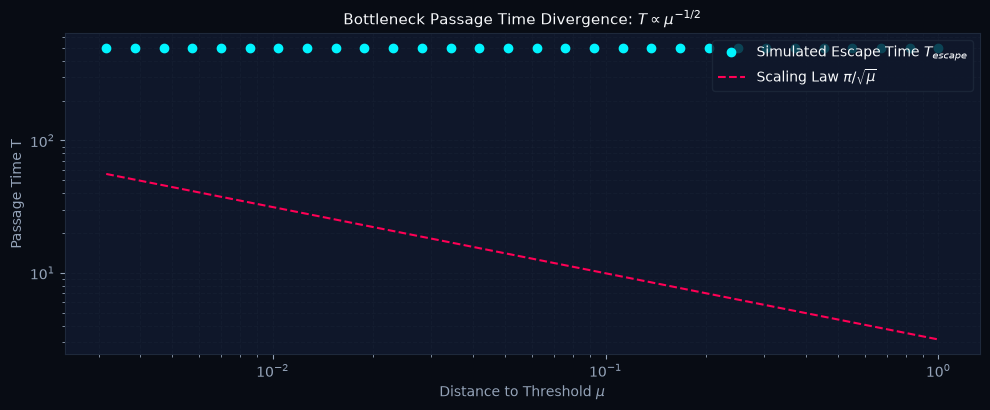

In [12]:
# LAB 2.2: THE GHOST OF SADDLE-NODE (BOTTLENECK SCALING)
display(HTML(create_dashboard_header(
    'LAB 2.2: THE GHOST OF SADDLE-NODE & TIME BOTTLENECK',
    'Verify scaling law T_escape ~ pi / sqrt(mu) as mu approaches zero from above.'
)))

mu_test_vals = np.logspace(-2.5, 0.0, 30)
passage_times = [measure_saddle_node_bottleneck(m, x_init=-2.0, x_target=2.0) for m in mu_test_vals]
theoretical_times = np.pi / np.sqrt(mu_test_vals)

fig, ax = plt.subplots(figsize=(10, 4.2), dpi=100)
ax.loglog(mu_test_vals, passage_times, 'o', color=PALETTE['cyan'], label=r'Simulated Escape Time $T_{escape}$')
ax.loglog(mu_test_vals, theoretical_times, '--', color=PALETTE['crimson'], lw=1.5, label=r'Scaling Law $\pi / \sqrt{\mu}$')
ax.set_title(r'Bottleneck Passage Time Divergence: $T \propto \mu^{-1/2}$', fontsize=11)
ax.set_xlabel(r'Distance to Threshold $\mu$', fontsize=10)
ax.set_ylabel('Passage Time T', fontsize=10)
ax.grid(True, which='both', linestyle='--', alpha=0.3)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
# LAB 2.3: SPRUCE BUDWORM OUTBREAK & HYSTERESIS ENGINE
display(HTML(create_dashboard_header(
    'LAB 2.3: SPRUCE BUDWORM OUTBREAK & HYSTERESIS LOOP',
    'Ludwig-Holling model: Observe catastrophic jump to outbreak and sluggish backward recovery.'
)))

def render_budworm_dashboard(r_growth, k_capacity):
    x_range = np.linspace(0.0, 25.0, 800)
    growth_curve = budworm_growth(x_range, r=r_growth, k=k_capacity)
    pred_curve = bird_predation(x_range)
    net_flow = growth_curve - pred_curve

    fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), dpi=100)
    # Panel A: Tug-of-war Curves
    axs[0].plot(x_range, growth_curve, color=PALETTE['emerald'], lw=1.5, label='Logistic Growth')
    axs[0].plot(x_range, pred_curve, color=PALETTE['crimson'], lw=1.5, label='Bird Predation')
    axs[0].set_title(f'Ecological Tug-of-War | r={r_growth:.2f}, k={k_capacity:.1f}', fontsize=11)
    axs[0].set_xlabel('Budworm Population x', fontsize=10)
    axs[0].set_ylabel('Rate of Change', fontsize=10)
    axs[0].set_ylim(0, 1.2)
    axs[0].legend(loc='upper right')

    # Panel B: Hysteresis S-Curve Loop
    k_arr = np.linspace(5.0, 22.0, 50)
    k_vals, fwd_x, bwd_x = simulate_budworm_hysteresis(r=r_growth, k_values=k_arr, steps_per_k=200)
    axs[1].plot(k_vals, fwd_x, color=PALETTE['cyan'], lw=1.8, label='Forward Driving (k increasing)')
    axs[1].plot(k_vals, bwd_x, '--', color=PALETTE['amber'], lw=1.8, label='Backward Driving (k decreasing)')
    axs[1].axvline(k_capacity, color=PALETTE['text_muted'], linestyle=':', lw=1.2, label=f'Current k={k_capacity:.1f}')
    axs[1].set_title('Catastrophic Hysteresis Loop (Outbreak vs. Refuge)', fontsize=11)
    axs[1].set_xlabel('Carrying Capacity k (Foliage Density)', fontsize=10)
    axs[1].set_ylabel('Equilibrium Population x*', fontsize=10)
    axs[1].legend(loc='upper left')
    plt.tight_layout()
    plt.show()

r_slider = widgets.FloatSlider(value=0.45, min=0.2, max=0.8, step=0.05, description='Growth r:', layout=widgets.Layout(width='380px'))
k_slider = widgets.FloatSlider(value=14.0, min=6.0, max=22.0, step=0.5, description='Foliage k:', layout=widgets.Layout(width='380px'))
ui_bud = widgets.HBox([r_slider, k_slider], layout=widgets.Layout(padding='10px', background_color=PALETTE['surface'], border='1px solid ' + PALETTE['border'], border_radius='8px'))
out_bud = widgets.interactive_output(render_budworm_dashboard, {'r_growth': r_slider, 'k_capacity': k_slider})
display(ui_bud, out_bud)

Output()